In [ ]:
#2024.6.26更新
#用346再做一遍
import os

folder_path = '/home/lihaoxing/500k_matrix_bed/346'  # 替换为你想要遍历的文件夹的路径

for filenames in os.listdir(folder_path):
    filename = os.path.join(folder_path, filenames)
    filename_part1 = filename.split('/')
    filename_part2 = filename_part1[5].split('_')
    print(filename_part2[0])
    with open('/home/lihaoxing/jupyter/500k_bin_range.txt', 'r') as f1:
        for line1 in f1.readlines():
            chr,min_bin,max_bin = line1.strip().split('\t')
            delta = int(int(min_bin)-1)
            # 处理每一行的内容，例如打印第一个字
            #print(chr,min_bin,max_bin)
            with open(filename, 'r') as f2:
                for line2 in f2.readlines():
                    bin1,bin2,counts = line2.strip().split('\t')
                    if int(min_bin) <=int(bin1) <=int(int(max_bin)-1) and int(min_bin) <=int(bin2) <=int(int(max_bin)-1):
                        #print(bin1+"\t"+bin2+"\t"+counts+"\n")
                        with open('/home/lihaoxing/try_scHiCluster/346_cell_matrix_500k/chr'+chr+"/"+filename_part2[0]+'_chr'+chr+'.txt', 'a') as f3:
                            f3.write(str(int(bin1)-int(delta))+"\t"+str(int(bin2)-int(delta))+"\t"+counts+"\n")

In [ ]:
#2024.6.26更新
#用346再做一遍
#随后在bash中运行如下命令
conda activate schicluster
res=500000
ls /home/lihaoxing/500k_matrix_bed/346/* |awk -F '/' '{print$6}'|awk -F '_' '{print$1}' >346_cell_list.txt

#首先创建文件夹
for c in `seq 1 18`; do mkdir -p 346_cell_matrix_500k/chr${c}/; done
for c in `seq 1 18`; do mkdir -p 346_imputed_matrix_500k/chr${c}/; done
mkdir 346_imputed_matrix_500k/filelist/
mkdir -p 346_imputed_matrix_500k/merged/embed/

#下面的命令写在sh脚本里,用nohup运行，需要很长时间
cat 346_cell_list.txt |while read line; do for c in `seq 1 18`; do command time hicluster impute-cell --indir 346_cell_matrix_500k/chr${c}/ --outdir 346_imputed_matrix_500k/chr${c}/ --cell $line --chrom ${c} --res 500000 --chrom_file /home/lihaoxing/HiC-Pro-3.1.0/annotation/Sus_scrofa.chrom.schicluster.size; done; done

awk -F "-" '{print $0"\t"$1}' 346_cell_list.txt > 346_cell_type.txt

for c in `seq 1 18`; do awk -v c=$c '{printf("346_imputed_matrix_500k/chr%s/%s_chr%s_pad1_std1_rp0.5_sqrtvc.hdf5\n",c,$1,c)}' 346_cell_type.txt > 346_imputed_matrix_500k/filelist/imputelist_pad1_std1_rp0.5_sqrtvc_chr${c}.txt; echo $c; done


#下面的命令会报错`np.str` was a deprecated alias for the builtin `str`. To avoid this error in existing code, use `str` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.str_` here.
#需要将/home/lihaoxing/miniconda3/lib/python3.9/site-packages/schicluster/draft/embed_concatcell_chr.py中的np.str修改为str
for c in `seq 1 18`; do command time hicluster embed-concatcell-chr --cell_list 346_imputed_matrix_500k/filelist/imputelist_pad1_std1_rp0.5_sqrtvc_chr${c}.txt --outprefix 346_imputed_matrix_500k/merged/embed/pad1_std1_rp0.5_sqrtvc_chr${c} --res 500000; done

ls 346_imputed_matrix_500k/merged/embed/*npy > 346_imputed_matrix_500k/filelist/embedlist_pad1_std1_rp0.5_sqrtvc.txt

#需要将/home/lihaoxing/miniconda3/lib/python3.9/site-packages/schicluster/draft/embed_mergechr.py 中的np.str修改为str
command time hicluster embed-mergechr --embed_list 346_imputed_matrix_500k/filelist/embedlist_pad1_std1_rp0.5_sqrtvc.txt --outprefix 346_imputed_matrix_500k/merged/embed/pad1_std1_rp0.5_sqrtvc

6


/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


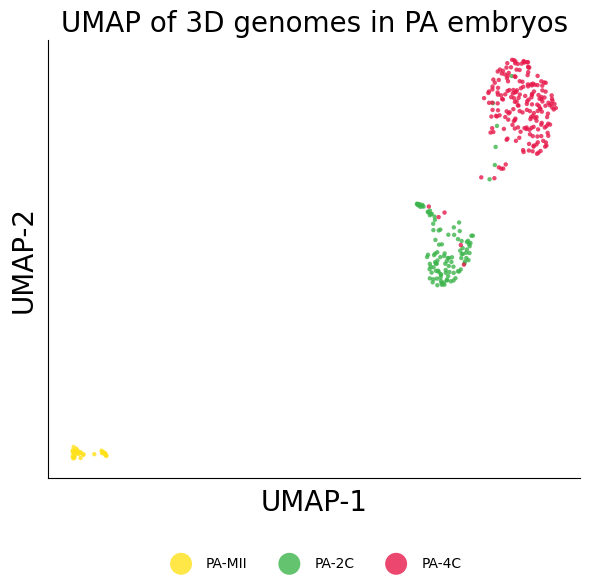

In [3]:
# PA 500K 346cells (优化版)
import h5py
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp
from sklearn.cluster import KMeans
from umap import UMAP
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

color_map = {
    "MII": "#ffe119",
    "2C": "#3cb44b",
    "4C": "#e6194b"
}

with h5py.File('/home/lihaoxing/try_scHiCluster/346_imputed_matrix_500k/merged/embed/pad1_std1_rp0.5_sqrtvc.svd20.hdf5', 'r') as f:
    matrix_reduce = f['data'][()]

for ndim in range(100):
    p = ks_2samp(matrix_reduce[:, ndim], matrix_reduce[:, ndim + 1]).pvalue
    if p > 0.01:
        break
ndim += 1
print(ndim)
ndim = 20

umap = UMAP(n_neighbors=25, random_state=0)
y = umap.fit_transform(matrix_reduce[:, :ndim])

label = pd.read_csv('/home/lihaoxing/try_scHiCluster/346_cell_type.txt', sep='\t', header=None, index_col=0)
label['batch'] = ['_'.join(x.split('_')[:2]) for x in label.index]

kmeans = KMeans(n_clusters=3, random_state=0).fit(matrix_reduce[:, :ndim])
label['cluster'] = kmeans.labels_ + 1

umap_df = pd.DataFrame(y, columns=['UMAP-1', 'UMAP-2'])
umap_df['Cell_ID'] = label['batch'].values
umap_df['Cell_Type'] = label[1].values
umap_df['Cluster'] = label['cluster'].values
umap_df.to_csv('346_500k_umap_embeddings_optimized.csv', index=True)

ds = 10
fig, ax = plt.subplots(figsize=(6, 6))  # 尺寸统一为6x6
ax.set_xlabel('UMAP-1', fontsize=20)
ax.set_ylabel('UMAP-2', fontsize=20)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.tick_params(axis='both', which='both', length=0)
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_title('UMAP of 3D genomes in PA embryos', fontsize=20)

for cell_type, color in color_map.items():
    cell = (label[1] == cell_type)
    ax.scatter(y[cell, 0], y[cell, 1], c=color, s=ds,
               edgecolors='none', alpha=0.8, label=f"PA-{cell_type}", rasterized=True)

# 图例移至下方居中，与IVF一致
ax.legend(markerscale=5, prop={'size': 10}, bbox_to_anchor=(0.5, -0.15),
          loc='upper center', fontsize=12, frameon=False, ncol=3)

plt.tight_layout()
plt.savefig('PA_346_500k_optimized.svg', dpi=300, bbox_inches='tight', transparent=True)
# plt.show()

In [ ]:
#IVF 350,500k,2024年11月28日

import os

folder_path = '/home/lihaoxing/IVF_500k_matrix'  # 替换为你想要遍历的文件夹的路径

for filenames in os.listdir(folder_path):
    filename = os.path.join(folder_path, filenames)
    filename_part1 = filename.split('/')
    filename_part2 = filename_part1[4].split('_')
    print(filename_part2[0])
    with open('/home/lihaoxing/jupyter/500k_bin_range.txt', 'r') as f1:
        for line1 in f1.readlines():
            chr,min_bin,max_bin = line1.strip().split('\t')
            delta = int(int(min_bin)-1)
            # 处理每一行的内容，例如打印第一个字
            #print(chr,min_bin,max_bin)
            with open(filename, 'r') as f2:
                for line2 in f2.readlines():
                    bin1,bin2,counts = line2.strip().split('\t')
                    if int(min_bin) <=int(bin1) <=int(int(max_bin)-1) and int(min_bin) <=int(bin2) <=int(int(max_bin)-1):
                        #print(bin1+"\t"+bin2+"\t"+counts+"\n")
                        with open('/home/lihaoxing/try_scHiCluster/IVF350_cell_matrix_500k/chr'+chr+"/"+filename_part2[0]+'_chr'+chr+'.txt', 'a') as f3:
                            f3.write(str(int(bin1)-int(delta))+"\t"+str(int(bin2)-int(delta))+"\t"+counts+"\n")

In [ ]:
#IVF 350,500k

#随后在bash中运行如下命令
conda activate schicluster
res=500000
ls /home/lihaoxing/IVF_500k_matrix/* |awk -F '/' '{print$5}'|awk -F '_' '{print$1}' >IVF350_cell_list.txt

#首先创建文件夹
for c in `seq 1 18`; do mkdir -p IVF350_cell_matrix_500k/chr${c}/; done
for c in `seq 1 18`; do mkdir -p IVF350_imputed_matrix_500k/chr${c}/; done
mkdir IVF350_imputed_matrix_500k/filelist/
mkdir -p IVF350_imputed_matrix_500k/merged/embed/

#下面的命令写在sh脚本里,用nohup运行，需要很长时间
cat IVF350_cell_list.txt |while read line; do for c in `seq 1 18`; do command time hicluster impute-cell --indir IVF350_cell_matrix_500k/chr${c}/ --outdir IVF350_imputed_matrix_500k/chr${c}/ --cell $line --chrom ${c} --res 500000 --chrom_file /home/lihaoxing/HiC-Pro-3.1.0/annotation/Sus_scrofa.chrom.schicluster.size; done; done

awk -F "-" '{print $0"\t"$2}' IVF350_cell_list.txt > IVF350_cell_type.txt

for c in `seq 1 18`; do awk -v c=$c '{printf("IVF350_imputed_matrix_500k/chr%s/%s_chr%s_pad1_std1_rp0.5_sqrtvc.hdf5\n",c,$1,c)}' IVF350_cell_type.txt > IVF350_imputed_matrix_500k/filelist/imputelist_pad1_std1_rp0.5_sqrtvc_chr${c}.txt; echo $c; done

#下面的命令会报错`np.str` was a deprecated alias for the builtin `str`. To avoid this error in existing code, use `str` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.str_` here.
#需要将/home/lihaoxing/miniconda3/lib/python3.9/site-packages/schicluster/draft/embed_concatcell_chr.py中的np.str修改为str
for c in `seq 1 18`; do command time hicluster embed-concatcell-chr --cell_list IVF350_imputed_matrix_500k/filelist/imputelist_pad1_std1_rp0.5_sqrtvc_chr${c}.txt --outprefix IVF350_imputed_matrix_500k/merged/embed/pad1_std1_rp0.5_sqrtvc_chr${c} --res 500000; done

ls IVF350_imputed_matrix_500k/merged/embed/*npy > IVF350_imputed_matrix_500k/filelist/embedlist_pad1_std1_rp0.5_sqrtvc.txt

#需要将/home/lihaoxing/miniconda3/lib/python3.9/site-packages/schicluster/draft/embed_mergechr.py 中的np.str修改为str
command time hicluster embed-mergechr --embed_list IVF350_imputed_matrix_500k/filelist/embedlist_pad1_std1_rp0.5_sqrtvc.txt --outprefix IVF350_imputed_matrix_500k/merged/embed/pad1_std1_rp0.5_sqrtvc

2


/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


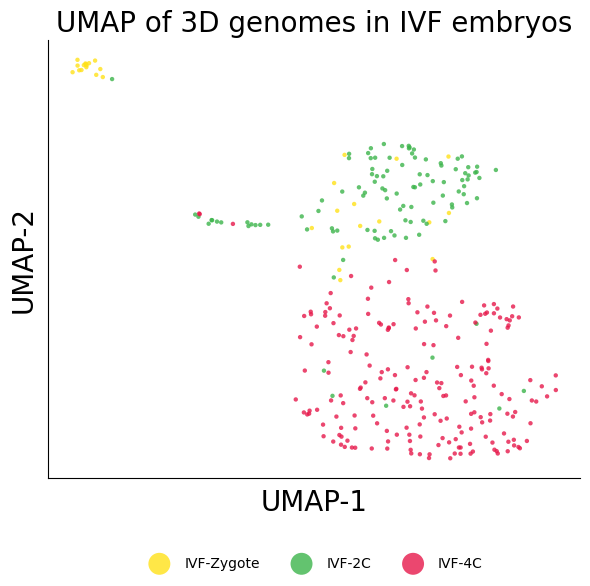

In [2]:
#IVF 350,500k
import h5py
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp
from sklearn.cluster import KMeans  # 导入KMeans
from umap import UMAP
from itertools import cycle, islice
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm as cm
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'


# 自定义颜色
color_map = {
    "Zygote": "#ffe119",  # 黄色
    "2C": "#3cb44b",  # 绿色
    "4C": "#e6194b"   # 红色
}

# 加载嵌入数据
with h5py.File('/home/lihaoxing/try_scHiCluster/IVF350_imputed_matrix_500k/merged/embed/pad1_std1_rp0.5_sqrtvc.svd20.hdf5', 'r') as f:
    matrix_reduce = f['data'][()]

# 确定使用的维度数量
for ndim in range(100):
    p = ks_2samp(matrix_reduce[:, ndim], matrix_reduce[:, ndim + 1]).pvalue
    if p > 0.01:
        break

ndim += 1
print(ndim)
ndim = 20  # 可手动调整维度
umap = UMAP(n_neighbors=25, random_state=0)
y = umap.fit_transform(matrix_reduce[:, :ndim])

# 加载标签数据
label = pd.read_csv('/home/lihaoxing/try_scHiCluster/IVF350_cell_type.txt', sep='\t', header=None, index_col=0)
label['batch'] = ['_'.join(x.split('_')[:2]) for x in label.index]

# 进行聚类
kmeans = KMeans(n_clusters=3, random_state=0).fit(matrix_reduce[:, :ndim])
label['cluster'] = kmeans.labels_ + 1

# 保存UMAP坐标和标签到CSV
umap_df = pd.DataFrame(y, columns=['UMAP-1', 'UMAP-2'])
umap_df['Cell_ID'] = label['batch'].values
umap_df['Cell_Type'] = label[1].values
umap_df['Cluster'] = label['cluster'].values
umap_df.to_csv('IVF350_500k_umap_embeddings.csv', index=True)

# 绘图
ds = 10
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlabel('UMAP-1', fontsize=20)
ax.set_ylabel('UMAP-2', fontsize=20)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.tick_params(axis='both', which='both', length=0)
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_title('UMAP of 3D genomes in IVF embryos', fontsize=20)

# 按细胞类型绘制散点图
for cell_type, color in color_map.items():
    cell = (label[1] == cell_type)
    ax.scatter(
        y[cell, 0],
        y[cell, 1],
        c=color,
        s=ds,
        edgecolors='none',
        alpha=0.8,
        label=f"IVF-{cell_type}",  # 修改图例标注
        rasterized=True
    )

# 调整图例
ax.legend(
    markerscale=5,
    prop={'size': 10},
    bbox_to_anchor=(0.5, -0.15),  # 放到图下方居中
    loc='upper center',
    fontsize=15,
    frameon=False,
    ncol=3  # 三类细胞横向排开
)

# 自动调整布局
plt.tight_layout()

# 保存图像
plt.savefig('IVF_350_500k.svg', dpi=300, bbox_inches='tight', transparent=True)